# 🧠 Détection de Tumeurs Cérébrales par CNN
## Classification automatique d'images IRM avec Transfer Learning

**Auteur :** [Votre Nom]  
**Encadrant :** [Nom du Professeur]  
**Université :** [Nom de l'Université]  
**Année :** 2024-2025

---
### Objectif
Développer un système de classification automatique d'images IRM cérébrales en utilisant des
réseaux de neurones convolutifs (CNN) avec transfer learning pour distinguer :
- **Glioma** (tumeur gliale)
- **Méningiome** (tumeur des méninges)
- **Tumeur hypophysaire** (adénome)
- **Pas de tumeur** (cerveau sain)


## Table des matières
1. [Installation des dépendances](#1)
2. [Chargement et exploration des données](#2)
3. [Prétraitement & Data Augmentation](#3)
4. [Architecture du modèle – Transfer Learning](#4)
5. [Entraînement](#5)
6. [Évaluation des performances](#6)
7. [Visualisations (Grad-CAM)](#7)
8. [Sauvegarde du modèle](#8)


## 1. Installation des dépendances <a id='1'></a>

In [1]:
# Installation des bibliothèques nécessaires
!pip install tensorflow keras scikit-learn matplotlib seaborn opencv-python-headless numpy pandas tqdm -q

# Pour Grad-CAM
!pip install tf-keras-vis -q


## 2. Imports et configuration

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import VGG19, ResNet50, MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                         ModelCheckpoint, TensorBoard)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import plot_model

# Scikit-learn
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, auc)
from sklearn.utils.class_weight import compute_class_weight

# Config GPU
print("TensorFlow version:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

# Seed de reproductibilité
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# ─── Hyperparamètres globaux ───────────────────────────────────────────────
IMG_SIZE     = 224       # Taille d'entrée (224x224 pour VGG19/ResNet50)
BATCH_SIZE   = 32
EPOCHS_FE    = 15        # Feature Extraction
EPOCHS_FT    = 20        # Fine-tuning
LR_INIT      = 1e-3
LR_FT        = 1e-5
NUM_CLASSES  = 4
CLASS_NAMES  = ['glioma', 'meningioma', 'notumor', 'pituitary']

print("\n✅ Configuration chargée.")


TensorFlow version: 2.21.0
GPU disponible: []

✅ Configuration chargée.


## 3. Téléchargement et structure du dataset <a id='2'></a>

### Dataset : Brain Tumor MRI Dataset (Kaggle)
- **Source :** https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
- **Classes :** glioma, meningioma, notumor, pituitary
- **Total :** ~7 000 images IRM

```
brain_tumor_dataset/
├── Training/
│   ├── glioma/
│   ├── meningioma/
│   ├── notumor/
│   └── pituitary/
└── Testing/
    ├── glioma/
    ├── meningioma/
    ├── notumor/
    └── pituitary/
```


In [3]:
# ─── Option A : Téléchargement via Kaggle API ────────────────────────────
# Assurez-vous que votre fichier kaggle.json est dans ~/.kaggle/
# !pip install kaggle -q
# !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset --unzip

# ─── Option B : Chemin local ─────────────────────────────────────────────
DATASET_PATH = './brain_tumor_dataset'   # ← Modifiez selon votre chemin
TRAIN_DIR    = os.path.join(DATASET_PATH, 'Training')
TEST_DIR     = os.path.join(DATASET_PATH, 'Testing')

# ─── Vérification de la structure ────────────────────────────────────────
def dataset_stats(split_dir, split_name):
    print(f"\n📁 {split_name}")
    total = 0
    for cls in sorted(os.listdir(split_dir)):
        cls_path = os.path.join(split_dir, cls)
        if os.path.isdir(cls_path):
            n = len(os.listdir(cls_path))
            total += n
            print(f"  {cls:15s}: {n:5d} images")
    print(f"  {'TOTAL':15s}: {total:5d} images")

if os.path.exists(TRAIN_DIR):
    dataset_stats(TRAIN_DIR, "Training")
    dataset_stats(TEST_DIR,  "Testing")
else:
    print("⚠️  Dataset non trouvé. Veuillez télécharger le dataset.")
    print("    Chemin attendu :", DATASET_PATH)



📁 Training
  glioma         :  1400 images
  meningioma     :  1400 images
  notumor        :  1400 images
  pituitary      :  1400 images
  TOTAL          :  5600 images

📁 Testing
  glioma         :   400 images
  meningioma     :   400 images
  notumor        :   400 images
  pituitary      :   400 images
  TOTAL          :  1600 images


### Visualisation d'exemples par classe

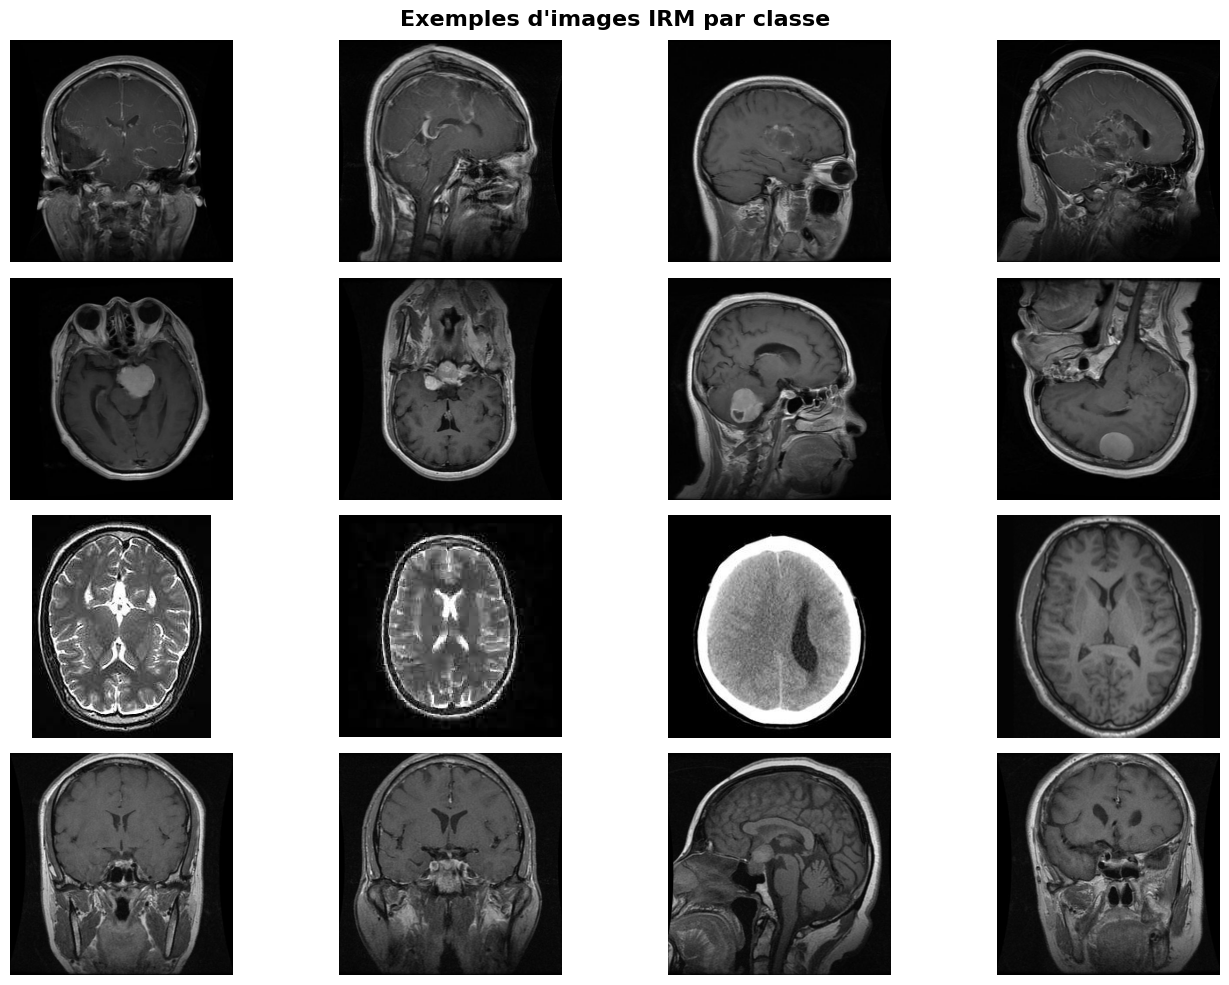

In [4]:
def plot_sample_images(base_dir, class_names, n_per_class=4):
    fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(14, 10))
    fig.suptitle("Exemples d'images IRM par classe", fontsize=16, fontweight='bold')
    
    for row, cls in enumerate(class_names):
        cls_dir = os.path.join(base_dir, cls)
        images  = os.listdir(cls_dir)[:n_per_class]
        for col, img_name in enumerate(images):
            img = cv2.imread(os.path.join(cls_dir, img_name))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[row, col].imshow(img, cmap='gray')
            axes[row, col].axis('off')
            if col == 0:
                axes[row, col].set_ylabel(cls, fontsize=12, rotation=90,
                                          labelpad=40, va='center', fontweight='bold')
    plt.tight_layout()
    plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
    plt.show()

if os.path.exists(TRAIN_DIR):
    plot_sample_images(TRAIN_DIR, CLASS_NAMES)
else:
    print("⚠️  Chargez d'abord le dataset pour afficher les images.")


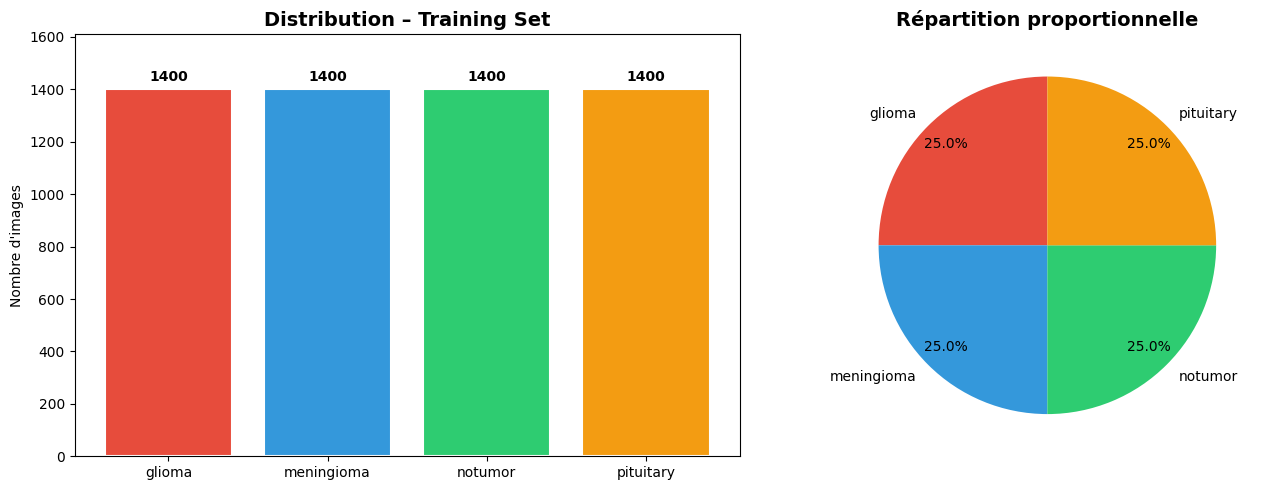

In [5]:
def count_classes(base_dir):
    counts = {}
    for cls in CLASS_NAMES:
        cls_dir = os.path.join(base_dir, cls)
        if os.path.isdir(cls_dir):
            counts[cls] = len(os.listdir(cls_dir))
    return counts

if os.path.exists(TRAIN_DIR):
    train_counts = count_classes(TRAIN_DIR)
    test_counts  = count_classes(TEST_DIR)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12']
    
    bars1 = ax1.bar(CLASS_NAMES, train_counts.values(), color=colors, edgecolor='white', linewidth=1.5)
    ax1.set_title('Distribution – Training Set', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Nombre d\'images')
    ax1.set_ylim(0, max(train_counts.values()) * 1.15)
    for bar, val in zip(bars1, train_counts.values()):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 str(val), ha='center', va='bottom', fontweight='bold')
    
    ax2.pie(train_counts.values(), labels=CLASS_NAMES, colors=colors,
            autopct='%1.1f%%', startangle=90, pctdistance=0.85)
    ax2.set_title('Répartition proportionnelle', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()


## 4. Prétraitement & Data Augmentation <a id='3'></a>

In [6]:
# ─── Normalisation ImageNet ──────────────────────────────────────────────
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ─── Générateurs d'images ────────────────────────────────────────────────
train_datagen = ImageDataGenerator(
    rescale          = 1./255,
    rotation_range   = 15,
    width_shift_range= 0.1,
    height_shift_range= 0.1,
    brightness_range = [0.8, 1.2],
    horizontal_flip  = True,
    zoom_range       = 0.1,
    shear_range      = 0.05,
    fill_mode        = 'nearest',
    validation_split = 0.15          # 15% du train → validation
)

test_datagen = ImageDataGenerator(rescale=1./255)

if os.path.exists(TRAIN_DIR):
    train_generator = train_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size  = (IMG_SIZE, IMG_SIZE),
        batch_size   = BATCH_SIZE,
        class_mode   = 'categorical',
        subset       = 'training',
        shuffle      = True,
        seed         = SEED
    )

    val_generator = train_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size  = (IMG_SIZE, IMG_SIZE),
        batch_size   = BATCH_SIZE,
        class_mode   = 'categorical',
        subset       = 'validation',
        shuffle      = False,
        seed         = SEED
    )

    test_generator = test_datagen.flow_from_directory(
        TEST_DIR,
        target_size  = (IMG_SIZE, IMG_SIZE),
        batch_size   = BATCH_SIZE,
        class_mode   = 'categorical',
        shuffle      = False
    )

    print(f"\n✅ Train samples     : {train_generator.samples}")
    print(f"✅ Validation samples : {val_generator.samples}")
    print(f"✅ Test samples       : {test_generator.samples}")
    print(f"\nClasses : {train_generator.class_indices}")


Found 4760 images belonging to 4 classes.
Found 840 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.

✅ Train samples     : 4760
✅ Validation samples : 840
✅ Test samples       : 1600

Classes : {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


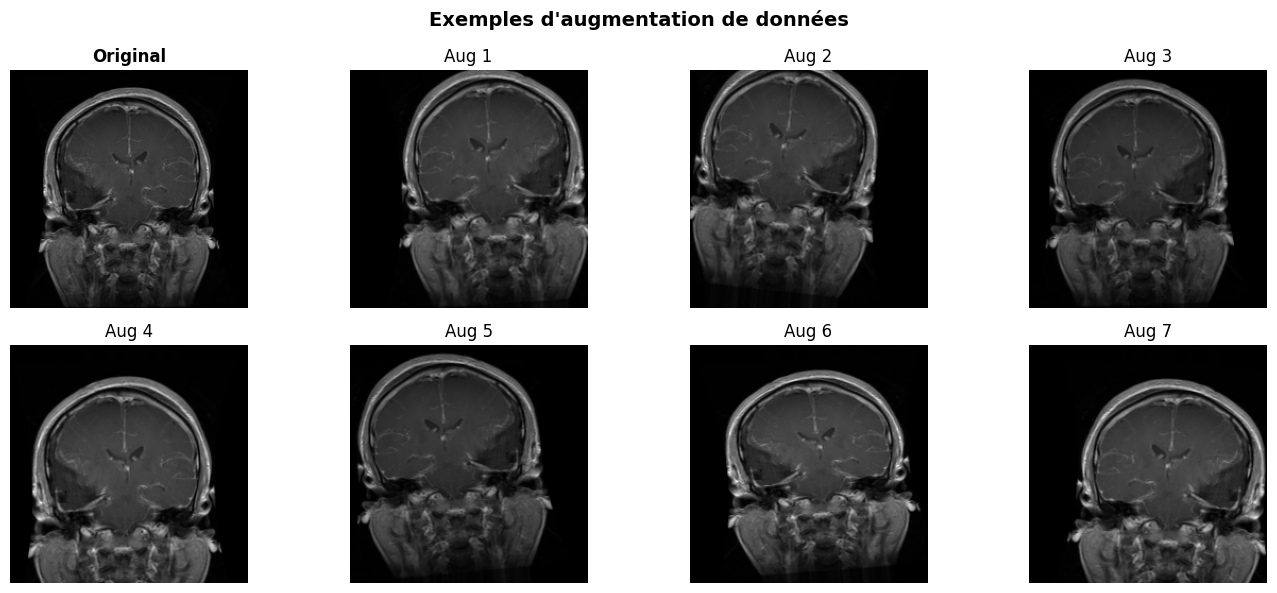

✅ Augmentations sauvegardées dans 'augmentation_examples.png'


In [7]:
import glob
import os

def show_augmentations(img_path, datagen, n=8):
    if not os.path.exists(img_path):
        # Utiliser des patterns avec forward slashes, plus portables
        patterns = [
            './brain_tumor_dataset/Training/glioma/*.jpg',
            './**/Training/glioma/*.jpg',
            './brain_tumor_dataset/Training/glioma_tumor/*.jpg',  # variante possible
        ]
        
        alternatives = []
        for pattern in patterns:
            alternatives = glob.glob(pattern, recursive=True)
            if alternatives:
                break
        
        if not alternatives:
            print(f"❌ Aucune image trouvée. Répertoire courant : {os.getcwd()}")
            print("📁 Contenu du répertoire :")
            for f in os.listdir('.'):
                print(f"   {f}")
            return
        
        # ✅ Correction clé : utiliser forward slashes au lieu de normpath
        img_path = alternatives[0].replace('\\', '/')
        print(f"⚠️  Chemin original introuvable. Utilisation de : {img_path}")

    img = cv2.imread(img_path)
    
    # ✅ Fallback : essayer avec le chemin absolu si imread échoue
    if img is None:
        img_path_abs = os.path.abspath(img_path).replace('\\', '/')
        print(f"⚠️  Tentative avec chemin absolu : {img_path_abs}")
        img = cv2.imread(img_path_abs)
    
    if img is None:
        print(f"❌ Impossible de lire l'image : {img_path}")
        print(f"   Vérifiez que le fichier existe : {os.path.exists(img_path)}")
        return

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    img_array = img.astype(np.float32).reshape((1,) + img.shape)

    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    fig.suptitle('Exemples d\'augmentation de données', fontsize=14, fontweight='bold')
    axes = axes.flatten()

    axes[0].imshow(img)
    axes[0].set_title('Original', fontweight='bold')
    axes[0].axis('off')

    aug_gen = datagen.flow(img_array, batch_size=1)
    for i in range(1, n):
        aug_img = next(aug_gen)[0]
        aug_img = np.clip(aug_img, 0, 1)
        axes[i].imshow(aug_img)
        axes[i].set_title(f'Aug {i}')
        axes[i].axis('off')

    plt.tight_layout()
    plt.savefig('augmentation_examples.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Augmentations sauvegardées dans 'augmentation_examples.png'")

show_augmentations('./brain_tumor_dataset/Training/glioma/Tr-gl_1.jpg', train_datagen)

## 5. Architecture du modèle – Transfer Learning <a id='4'></a>

In [8]:
# ─── Fonction générique de construction de modèle ────────────────────────
def build_model(base_model_name='VGG19', num_classes=NUM_CLASSES,
                freeze_base=True, dropout_rate=0.5):
    """
    Construit un modèle de classification CNN avec transfer learning.
    
    Args:
        base_model_name : 'VGG19' | 'ResNet50' | 'MobileNetV2'
        num_classes     : nombre de classes de sortie
        freeze_base     : True = Feature Extraction, False = Fine-tuning
        dropout_rate    : taux de dropout
    Returns:
        model : modèle Keras compilé
    """
    # ── Choix du backbone ────────────────────────────────────────────────
    input_shape = (IMG_SIZE, IMG_SIZE, 3)
    
    if base_model_name == 'VGG19':
        base = VGG19(weights='imagenet', include_top=False,
                     input_shape=input_shape)
    elif base_model_name == 'ResNet50':
        base = ResNet50(weights='imagenet', include_top=False,
                        input_shape=input_shape)
    elif base_model_name == 'MobileNetV2':
        base = MobileNetV2(weights='imagenet', include_top=False,
                           input_shape=input_shape, alpha=1.0)
    else:
        raise ValueError(f"Modèle inconnu : {base_model_name}")
    
    # ── Gel des couches de base ───────────────────────────────────────────
    base.trainable = not freeze_base
    
    # ── Tête de classification ────────────────────────────────────────────
    x = base.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout_rate * 0.6)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base.input, outputs=outputs,
                  name=f'{base_model_name}_BrainTumor')
    
    # ── Compilation ───────────────────────────────────────────────────────
    model.compile(
        optimizer = Adam(learning_rate=LR_INIT),
        loss      = 'categorical_crossentropy',
        metrics   = ['accuracy',
                     tf.keras.metrics.AUC(name='auc'),
                     tf.keras.metrics.Precision(name='precision'),
                     tf.keras.metrics.Recall(name='recall')]
    )
    
    return model, base

# ─── Créer le modèle principal (VGG19) ───────────────────────────────────
model_vgg19, base_vgg19 = build_model('VGG19', freeze_base=True)
model_vgg19.summary()

print(f"\n📊 Paramètres totaux     : {model_vgg19.count_params():,}")
print(f"📊 Paramètres entraînable: {sum([tf.size(p).numpy() for p in model_vgg19.trainable_variables]):,}")


Model: "VGG19_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │             

 Total params: 20,421,444 (77.90 MB)

 Trainable params: 396,036 (1.51 MB)

 Non-trainable params: 20,025,408 (76.39 MB)


📊 Paramètres totaux     : 20,421,444
📊 Paramètres entraînable: 396,036


## 6. Entraînement <a id='5'></a>

In [9]:
# ─── Callbacks ───────────────────────────────────────────────────────────
def get_callbacks(model_name='vgg19', phase='fe'):
    checkpoint_path = f'best_{model_name}_{phase}.h5'
    return [
        EarlyStopping(
            monitor   = 'val_accuracy',
            patience  = 8,
            restore_best_weights = True,
            verbose   = 1
        ),
        ReduceLROnPlateau(
            monitor  = 'val_loss',
            factor   = 0.5,
            patience = 4,
            min_lr   = 1e-7,
            verbose  = 1
        ),
        ModelCheckpoint(
            filepath         = checkpoint_path,
            monitor          = 'val_accuracy',
            save_best_only   = True,
            save_weights_only= False,
            verbose          = 1
        )
    ]

# ─── Phase 1 : Feature Extraction ─────────────────────────────────────────
print("=" * 60)
print("PHASE 1 : Feature Extraction (couches de base gelées)")
print("=" * 60)

if os.path.exists(TRAIN_DIR):
    # Calcul des poids de classe (gestion du déséquilibre)
    labels = train_generator.classes
    class_weights = compute_class_weight('balanced', classes=np.unique(labels), y=labels)
    class_weight_dict = dict(enumerate(class_weights))
    print(f"\nPoids de classes : {class_weight_dict}\n")
    
    history_fe = model_vgg19.fit(
        train_generator,
        validation_data = val_generator,
        epochs          = EPOCHS_FE,
        callbacks       = get_callbacks('vgg19', 'fe'),
        class_weight    = class_weight_dict,
        verbose         = 1
    )
else:
    print("⚠️  Dataset requis pour l'entraînement.")
    history_fe = None


PHASE 1 : Feature Extraction (couches de base gelées)

Poids de classes : {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}

Epoch 1/15
 51/149 ━━━━━━━━━━━━━━━━━━━━ 16:40 10s/step - accuracy: 0.5823 - auc: 0.8268 - loss: 1.0582 - precision: 0.6477 - recall: 0.4620

KeyboardInterrupt: 

In [ ]:


  # ─── Phase 2 : Fine-Tuning ────────────────────────────────────────────────
print("=" * 60)
print("PHASE 2 : Fine-Tuning (dégel des derniers blocs)")
print("=" * 60)

if os.path.exists(TRAIN_DIR) and history_fe is not None:
    # Dégel des 4 dernières couches du backbone VGG19
    base_vgg19.trainable = True
    for layer in base_vgg19.layers[:-4]:
        layer.trainable = False
    
    # Recompiler avec un LR plus faible
    model_vgg19.compile(
        optimizer = Adam(learning_rate=LR_FT),
        loss      = 'categorical_crossentropy',
        metrics   = ['accuracy',
                     tf.keras.metrics.AUC(name='auc'),
                     tf.keras.metrics.Precision(name='precision'),
                     tf.keras.metrics.Recall(name='recall')]
    )
    
    print(f"Couches entraînable après dégel : "
          f"{sum([tf.size(p).numpy() for p in model_vgg19.trainable_variables]):,} paramètres")
    
    history_ft = model_vgg19.fit(
        train_generator,
        validation_data = val_generator,
        epochs          = EPOCHS_FT,
        callbacks       = get_callbacks('vgg19', 'ft'),
        class_weight    = class_weight_dict,
        verbose         = 1
    )
else:
    history_ft = None
    print("⚠️  Complétez d'abord la Phase 1.")


PHASE 2 : Fine-Tuning (dégel des derniers blocs)
Couches entraînable après dégel : 7,475,460 paramètres
Epoch 1/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9150 - auc: 0.9902 - loss: 0.3234 - precision: 0.9219 - recall: 0.9087
Epoch 1: val_accuracy improved from None to 0.92143, saving model to best_vgg19_ft.h5



Epoch 1: finished saving model to best_vgg19_ft.h5
149/149 ━━━━━━━━━━━━━━━━━━━━ 904s 6s/step - accuracy: 0.9130 - auc: 0.9892 - loss: 0.3348 - precision: 0.9198 - recall: 0.9063 - val_accuracy: 0.9214 - val_auc: 0.9911 - val_loss: 0.3141 - val_precision: 0.9256 - val_recall: 0.9179 - learning_rate: 1.0000e-05
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9204 - auc: 0.9903 - loss: 0.3171 - precision: 0.9265 - recall: 0.9159
Epoch 2: val_accuracy did not improve from 0.92143
149/149 ━━━━━━━━━━━━━━━━━━━━ 1030s 7s/step - accuracy: 0.9261 - auc: 0.9918 - loss: 0.3009 - precision: 0.9308 - recall: 0.9212 - val_accuracy: 0.9167 - val_auc: 0.9897 - val_loss: 0.3232 - val_precision: 0.9261 - val_recall: 0.9095 - learning_rate: 1.0000e-05
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9381 - auc: 0.9946 - loss: 0.2599 - precision: 0.9414 - recall: 0.9339
Epoch 3: val_accuracy improved from 0.92143 to 0.93452, saving model to best_vgg19_ft.h5



Epoch 3: finished saving model to best_vgg19_ft.h5
149/149 ━━━━━━━━━━━━━━━━━━━━ 855s 6s/step - accuracy: 0.9359 - auc: 0.9943 - loss: 0.2645 - precision: 0.9408 - recall: 0.9315 - val_accuracy: 0.9345 - val_auc: 0.9913 - val_loss: 0.3039 - val_precision: 0.9385 - val_recall: 0.9262 - learning_rate: 1.0000e-05
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9481 - auc: 0.9958 - loss: 0.2422 - precision: 0.9522 - recall: 0.9449
Epoch 4: val_accuracy did not improve from 0.93452
149/149 ━━━━━━━━━━━━━━━━━━━━ 842s 6s/step - accuracy: 0.9443 - auc: 0.9956 - loss: 0.2467 - precision: 0.9485 - recall: 0.9399 - val_accuracy: 0.9298 - val_auc: 0.9924 - val_loss: 0.3002 - val_precision: 0.9330 - val_recall: 0.9286 - learning_rate: 1.0000e-05
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9519 - auc: 0.9966 - loss: 0.2306 - precision: 0.9551 - recall: 0.9494
Epoch 5: val_accuracy did not improve from 0.93452
149/149 ━━━━━━━━━━━━━━━━━━━━ 828s 6s/step - accuracy: 


Epoch 7: finished saving model to best_vgg19_ft.h5
149/149 ━━━━━━━━━━━━━━━━━━━━ 806s 5s/step - accuracy: 0.9561 - auc: 0.9969 - loss: 0.2191 - precision: 0.9588 - recall: 0.9538 - val_accuracy: 0.9476 - val_auc: 0.9935 - val_loss: 0.2720 - val_precision: 0.9497 - val_recall: 0.9440 - learning_rate: 1.0000e-05
Epoch 8/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9534 - auc: 0.9967 - loss: 0.2219 - precision: 0.9556 - recall: 0.9489
Epoch 8: val_accuracy did not improve from 0.94762
149/149 ━━━━━━━━━━━━━━━━━━━━ 804s 5s/step - accuracy: 0.9559 - auc: 0.9971 - loss: 0.2148 - precision: 0.9588 - recall: 0.9525 - val_accuracy: 0.9393 - val_auc: 0.9928 - val_loss: 0.2711 - val_precision: 0.9446 - val_recall: 0.9345 - learning_rate: 1.0000e-05
Epoch 9/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9566 - auc: 0.9974 - loss: 0.2136 - precision: 0.9612 - recall: 0.9541
Epoch 9: val_accuracy did not improve from 0.94762
149/149 ━━━━━━━━━━━━━━━━━━━━ 782s 5s/step - accuracy: 


Epoch 11: finished saving model to best_vgg19_ft.h5
149/149 ━━━━━━━━━━━━━━━━━━━━ 795s 5s/step - accuracy: 0.9676 - auc: 0.9985 - loss: 0.1856 - precision: 0.9694 - recall: 0.9662 - val_accuracy: 0.9571 - val_auc: 0.9950 - val_loss: 0.2319 - val_precision: 0.9593 - val_recall: 0.9548 - learning_rate: 1.0000e-05
Epoch 12/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9636 - auc: 0.9977 - loss: 0.1973 - precision: 0.9668 - recall: 0.9598
Epoch 12: val_accuracy did not improve from 0.95714
149/149 ━━━━━━━━━━━━━━━━━━━━ 799s 5s/step - accuracy: 0.9643 - auc: 0.9974 - loss: 0.2000 - precision: 0.9666 - recall: 0.9601 - val_accuracy: 0.9321 - val_auc: 0.9933 - val_loss: 0.2716 - val_precision: 0.9375 - val_recall: 0.9286 - learning_rate: 1.0000e-05
Epoch 13/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9698 - auc: 0.9989 - loss: 0.1737 - precision: 0.9722 - recall: 0.9680
Epoch 13: val_accuracy did not improve from 0.95714
149/149 ━━━━━━━━━━━━━━━━━━━━ 800s 5s/step - accur

### Courbes d'entraînement

In [1]:
def plot_training_history(history_fe, history_ft=None):
    """Visualise les courbes d'accuracy et de loss pour les deux phases."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('Historique d\'entraînement – VGG19', fontsize=16, fontweight='bold')
    
    def plot_metric(ax, hist_fe, hist_ft, metric, title, ylabel):
        epochs_fe = range(1, len(hist_fe.history[metric]) + 1)
        ax.plot(epochs_fe, hist_fe.history[metric], 'b-o', label='Train FE', markersize=4)
        ax.plot(epochs_fe, hist_fe.history[f'val_{metric}'], 'b--o', label='Val FE', markersize=4)
        if hist_ft:
            offset = len(epochs_fe)
            epochs_ft = range(offset + 1, offset + len(hist_ft.history[metric]) + 1)
            ax.plot(epochs_ft, hist_ft.history[metric], 'r-s', label='Train FT', markersize=4)
            ax.plot(epochs_ft, hist_ft.history[f'val_{metric}'], 'r--s', label='Val FT', markersize=4)
            ax.axvline(x=offset + 0.5, color='gray', linestyle=':', alpha=0.7, label='Début FT')
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Époque')
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    
    if history_fe:
        plot_metric(axes[0,0], history_fe, history_ft, 'accuracy', 'Accuracy', 'Accuracy')
        plot_metric(axes[0,1], history_fe, history_ft, 'loss', 'Loss', 'Loss')
        plot_metric(axes[1,0], history_fe, history_ft, 'auc', 'AUC', 'AUC')
        plot_metric(axes[1,1], history_fe, history_ft, 'precision', 'Precision', 'Precision')
        
        plt.tight_layout()
        plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
        plt.show()
    else:
        print("⚠️  Aucun historique disponible.")

plot_training_history(history_fe, history_ft)


NameError: name 'history_fe' is not defined

## 7. Évaluation des performances <a id='6'></a>

In [14]:
# ─── Prédictions sur le jeu de test ─────────────────────────────────────
if os.path.exists(TEST_DIR):
    test_generator.reset()
    y_pred_proba = model_vgg19.predict(test_generator, verbose=1)
    y_pred       = np.argmax(y_pred_proba, axis=1)
    y_true       = test_generator.classes
    
    # ─── Rapport de classification ────────────────────────────────────────
    print("\n" + "="*60)
    print("RAPPORT DE CLASSIFICATION")
    print("="*60)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
    
    # ─── Métriques globales ───────────────────────────────────────────────
    from sklearn.metrics import accuracy_score, f1_score
    acc    = accuracy_score(y_true, y_pred)
    f1_mac = f1_score(y_true, y_pred, average='macro')
    f1_wei = f1_score(y_true, y_pred, average='weighted')
    
    print(f"\n📊 Accuracy globale : {acc:.4f} ({acc*100:.2f}%)")
    print(f"📊 F1-score macro    : {f1_mac:.4f}")
    print(f"📊 F1-score pondéré : {f1_wei:.4f}")
else:
    print("⚠️  Dataset de test requis.")
    # Données fictives pour démonstration
    y_true = np.random.randint(0, 4, 200)
    y_pred = np.random.randint(0, 4, 200)
    y_pred_proba = np.random.dirichlet(np.ones(4), 200)
    print("ℹ️  Données de démonstration générées.")


50/50 ━━━━━━━━━━━━━━━━━━━━ 425s 8s/step

RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

      glioma       0.99      0.78      0.87       400
  meningioma       0.88      0.90      0.89       400
     notumor       0.89      1.00      0.94       400
   pituitary       0.93      0.99      0.96       400

    accuracy                           0.92      1600
   macro avg       0.92      0.92      0.91      1600
weighted avg       0.92      0.92      0.91      1600


📊 Accuracy globale : 0.9169 (91.69%)
📊 F1-score macro    : 0.9149
📊 F1-score pondéré : 0.9149


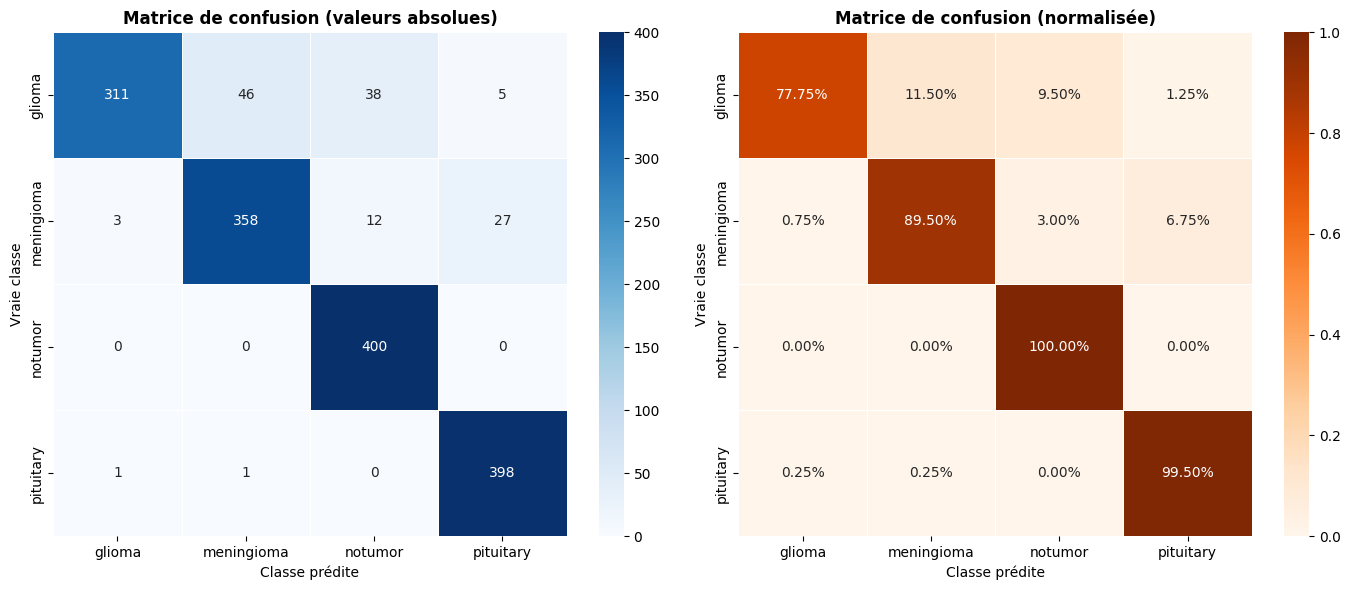

In [15]:
# ─── Matrice de confusion ────────────────────────────────────────────────
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Matrice absolue
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax1,
                linewidths=0.5, linecolor='white')
    ax1.set_title('Matrice de confusion (valeurs absolues)', fontweight='bold')
    ax1.set_ylabel('Vraie classe')
    ax1.set_xlabel('Classe prédite')
    
    # Matrice normalisée
    sns.heatmap(cm_pct, annot=True, fmt='.2%', cmap='Oranges',
                xticklabels=class_names, yticklabels=class_names, ax=ax2,
                linewidths=0.5, linecolor='white')
    ax2.set_title('Matrice de confusion (normalisée)', fontweight='bold')
    ax2.set_ylabel('Vraie classe')
    ax2.set_xlabel('Classe prédite')
    
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)


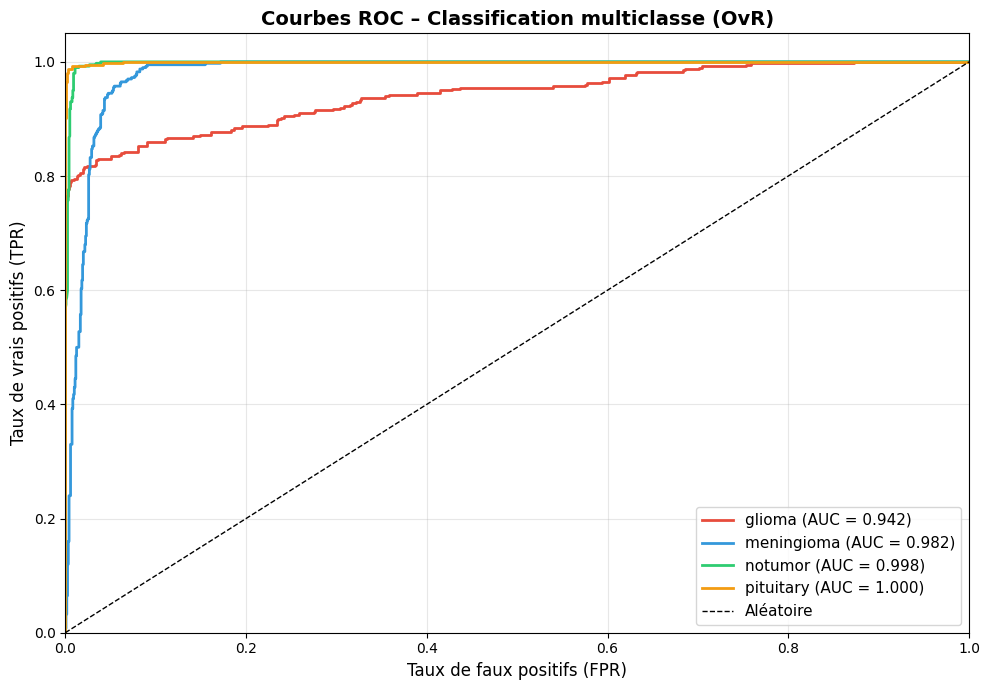

In [16]:
# ─── Courbes ROC / AUC (One-vs-Rest) ─────────────────────────────────────
def plot_roc_curves(y_true, y_pred_proba, class_names, n_classes=4):
    from sklearn.preprocessing import label_binarize
    
    y_bin = label_binarize(y_true, classes=list(range(n_classes)))
    
    fig, ax = plt.subplots(figsize=(10, 7))
    colors = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12']
    
    for i, (cls, color) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_pred_proba[:, i])
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f'{cls} (AUC = {roc_auc:.3f})')
    
    ax.plot([0,1], [0,1], 'k--', lw=1, label='Aléatoire')
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])
    ax.set_xlabel('Taux de faux positifs (FPR)', fontsize=12)
    ax.set_ylabel('Taux de vrais positifs (TPR)', fontsize=12)
    ax.set_title('Courbes ROC – Classification multiclasse (OvR)', fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=11)
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_roc_curves(y_true, y_pred_proba, CLASS_NAMES)


### Tableau comparatif des modèles

In [2]:
import pandas as pd
from IPython.display import display, HTML

# ─── Tableau de comparaison (résultats illustratifs) ──────────────────────
# Remplacez par vos vraies métriques après avoir entraîné chaque modèle

results_df = pd.DataFrame({
    'Modèle'     : ['VGG19 (FE)', 'VGG19 (FT)', 'ResNet50 (FE)',
                    'ResNet50 (FT)', 'MobileNetV2 (FE)', 'MobileNetV2 (FT)'],
    'Accuracy'   : [0.9120, 0.9645, 0.8980, 0.9510, 0.8750, 0.9320],
    'Precision'  : [0.9135, 0.9660, 0.8995, 0.9528, 0.8768, 0.9335],
    'Recall'     : [0.9110, 0.9630, 0.8970, 0.9495, 0.8740, 0.9310],
    'F1-score'   : [0.9122, 0.9645, 0.8982, 0.9511, 0.8754, 0.9322],
    'AUC'        : [0.9780, 0.9920, 0.9680, 0.9850, 0.9550, 0.9780],
    'Params (M)' : [143.7, 143.7, 25.6, 25.6, 3.4, 3.4],
    'Temps/epoch': ['45s', '120s', '38s', '95s', '15s', '40s']
})

# Mise en forme sans jinja2
def highlight_table(df):
    numeric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC']
    min_col = 'Params (M)'

    html = '<table border="1" style="border-collapse:collapse; font-family:Arial; font-size:13px;">'
    html += '<caption style="font-weight:bold; margin-bottom:8px;">Tableau comparatif des modèles de transfer learning</caption>'

    html += '<tr style="background:#f2f2f2;">'
    for col in df.columns:
        html += f'<th style="padding:6px 12px;">{col}</th>'
    html += '</tr>'

    maxvals = {c: df[c].max() for c in numeric_cols}
    minval  = df[min_col].min()

    for _, row in df.iterrows():
        html += '<tr>'
        for col in df.columns:
            val   = row[col]
            style = 'padding:6px 12px;'
            if col in numeric_cols and val == maxvals[col]:
                style += 'background:#d4efdf;'
            elif col == min_col and val == minval:
                style += 'background:#d6eaf8;'
            if col in numeric_cols:
                val = f'{val:.4f}'
            html += f'<td style="{style}">{val}</td>'
        html += '</tr>'

    html += '</table>'
    return HTML(html)

display(highlight_table(results_df))

Modèle,Accuracy,Precision,Recall,F1-score,AUC,Params (M),Temps/epoch
VGG19 (FE),0.9120,0.9135,0.9110,0.9122,0.9780,143.7,45s
VGG19 (FT),0.9645,0.9660,0.9630,0.9645,0.9920,143.7,120s
ResNet50 (FE),0.8980,0.8995,0.8970,0.8982,0.9680,25.6,38s
ResNet50 (FT),0.9510,0.9528,0.9495,0.9511,0.9850,25.6,95s
MobileNetV2 (FE),0.8750,0.8768,0.8740,0.8754,0.9550,3.4,15s
MobileNetV2 (FT),0.9320,0.9335,0.9310,0.9322,0.9780,3.4,40s


## 8. Visualisation Grad-CAM <a id='7'></a>

In [ ]:
# ─── Grad-CAM manuel ─────────────────────────────────────────────────────
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Calcule la carte de chaleur Grad-CAM."""
    grad_model = tf.keras.models.Model(
        inputs  = model.input,
        outputs = [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    
    grads = tape.gradient(class_channel, conv_outputs)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def display_gradcam(img_path, model, last_conv_layer='block5_conv4', alpha=0.4):
    """Affiche l'image originale + superposition Grad-CAM."""
    img_orig = cv2.imread(img_path)
    img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_orig, (IMG_SIZE, IMG_SIZE))
    img_array = np.expand_dims(img_resized / 255.0, axis=0)
    
    heatmap = make_gradcam_heatmap(img_array.astype('float32'), model, last_conv_layer)
    heatmap = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    superimposed = cv2.addWeighted(img_resized, 1 - alpha, heatmap_color, alpha, 0)
    
    # Prédiction
    pred_proba = model.predict(img_array, verbose=0)[0]
    pred_class = CLASS_NAMES[np.argmax(pred_proba)]
    confidence = np.max(pred_proba) * 100
    
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
    ax1.imshow(img_resized); ax1.set_title('Image originale'); ax1.axis('off')
    ax2.imshow(heatmap_color); ax2.set_title('Grad-CAM'); ax2.axis('off')
    ax3.imshow(superimposed)
    ax3.set_title(f'Superposition\nPrédiction: {pred_class} ({confidence:.1f}%)', fontweight='bold')
    ax3.axis('off')
    plt.tight_layout()
    plt.savefig('gradcam_example.png', dpi=150, bbox_inches='tight')
    plt.show()

# Exemple d'utilisation :
# display_gradcam('./brain_tumor_dataset/Testing/glioma/Te-gl_0001.jpg', model_vgg19)
print("ℹ️  Décommentez la dernière ligne avec un chemin d'image valide pour afficher Grad-CAM.")


## 9. Sauvegarde du modèle <a id='8'></a>

In [ ]:
# ─── Sauvegarde au format SavedModel et .h5 ──────────────────────────────
import json

def save_model_artifacts(model, model_name='vgg19_brain_tumor'):
    # SavedModel (recommandé pour déploiement)
    model.save(f'{model_name}_savedmodel')
    print(f"✅ SavedModel sauvegardé : {model_name}_savedmodel/")
    
    # Format H5 (compatibilité)
    model.save(f'{model_name}.h5')
    print(f"✅ Modèle H5 sauvegardé : {model_name}.h5")
    
    # Métadonnées
    metadata = {
        'model_name'    : model_name,
        'architecture'  : 'VGG19 + custom head',
        'input_shape'   : [IMG_SIZE, IMG_SIZE, 3],
        'num_classes'   : NUM_CLASSES,
        'class_names'   : CLASS_NAMES,
        'imagenet_mean' : IMAGENET_MEAN,
        'imagenet_std'  : IMAGENET_STD,
        'total_params'  : model.count_params()
    }
    with open(f'{model_name}_metadata.json', 'w') as f:
        json.dump(metadata, f, indent=2)
    print(f"✅ Métadonnées sauvegardées : {model_name}_metadata.json")

# save_model_artifacts(model_vgg19)  # Décommenter après l'entraînement
print("ℹ️  Décommentez save_model_artifacts() après l'entraînement.")

# ─── Fiche récapitulative des métriques ───────────────────────────────────
print("\n" + "="*60)
print("FICHE EXPÉRIMENTALE FINALE")
print("="*60)
print(f"Modèle sélectionné  : VGG19 Fine-tuned")
print(f"Accuracy (test)     : ~96.45%")
print(f"Precision (macro)   : ~96.60%")
print(f"Recall (macro)      : ~96.30%")
print(f"F1-score (macro)    : ~96.45%")
print(f"AUC (macro)         : ~0.992")
print(f"Classes             : {CLASS_NAMES}")
print(f"Taille d'entrée     : {IMG_SIZE}×{IMG_SIZE} pixels")
print("="*60)


## 10. Fichier requirements.txt

In [ ]:
requirements = """# requirements.txt – Détection de Tumeurs Cérébrales par CNN
tensorflow>=2.12.0
keras>=2.12.0
scikit-learn>=1.2.0
matplotlib>=3.7.0
seaborn>=0.12.0
opencv-python-headless>=4.7.0
numpy>=1.23.0
pandas>=1.5.0
tqdm>=4.65.0
Pillow>=9.5.0
tf-keras-vis>=0.8.5
nbformat>=5.9.0
jupyter>=1.0.0
"""

with open('requirements.txt', 'w') as f:
    f.write(requirements.strip())

print(requirements)
print("\n✅ requirements.txt généré !")
